# ECOSTRESS Collection 3 SATM Reproduction Notebook (`JET3`)

This notebook reproduces all tabular accuracy benchmarks, model intercomparisons, Monte Carlo one-at-a-time perturbation analyses, Sobol global variance decompositions ($S_1, S_T$), LOWESS main-effect curves, pairwise interaction maps, and predictor collinearity diagnostics presented in the two 2026 ECOSTRESS Science and Applications Team Meeting (SATM) presentations:

1. **`2026-08-12 ECOSTRESS Collection 3 Evapotranspiration Products`**
   * **Slide 4:** Collection 3 ensemble `LE_Wm2` ($R^2 = 0.61$, $\text{RMSE} = 91.92\text{ W m}^{-2}$) and `ET_daylight_kg` ($R^2 = 0.56$, $\text{RMSE} = 1.31\text{ kg}$) scatter validation ($N = 1{,}063$).
   * **Slide 5:** Collection 3 ensemble `LE_Wm2` benchmark ($R^2 = 0.61$, $\text{RMSE} = 91.92\text{ W m}^{-2}$) concluding the Collection 1 $\rightarrow$ Collection 2 $\rightarrow$ Collection 3 accuracy progression.
   * **Slides 8–9:** Constituent `BESS-JPL` (`LE_BESS_Wm2`: $R^2 = 0.55$, $\text{RMSE} = 109.48\text{ W m}^{-2}$) and `STIC-JPL` (`LE_STIC_Wm2`: $R^2 = 0.39$, $\text{RMSE} = 154.45\text{ W m}^{-2}$) scatter validation.
2. **`2026-08-12 Thermally Sensitive ECOSTRESS Evapotranspiration Model Ensemble Evaluation and Development`**
   * **Slide 3:** Cal-Val dataset filtering summary ($1{,}065$ total observations filtered at $\text{NDVI} \ge 0.05$).
   * **Slide 4:** `Verma` ($R^2 = 0.69$, $\text{RMSE} = 115.72\text{ W m}^{-2}$) vs. `BESS-JPL` ($R^2 = 0.54$, $\text{RMSE} = 116.27\text{ W m}^{-2}$) net radiation scatter validation.
   * **Slide 5:** Monte Carlo thermal sensitivity of `BESS-JPL` ($\approx 34.5\%$) vs. `Verma` ($\approx 17.7\%$) net radiation to `ST_C`.
   * **Slides 6–8:** Sobol sensitivity indices ($S_1, S_T$) and `ST_C` LOWESS main-effect curves for `Rn_BESS_Wm2` and `Rn_verma_Wm2`.
   * **Slide 9:** Latent heat flux accuracy across `PM-JPL`, `BESS-JPL`, `PT-JPL-SM`, and `STIC-JPL`.
   * **Slides 10–11:** Monte Carlo sensitivity magnitude bar charts and $\Delta ST_C$ vs. $\Delta LE$ perturbation scatter plots across all four constituent `LE` models.
   * **Slides 12–13:** Sobol sensitivity indices ($S_1, S_T$) for `LE_PTJPLSM_Wm2`, `LE_PMJPL_Wm2`, `LE_BESS_Wm2`, and `LE_STIC_Wm2`.
   * **Slide 14:** Sobol `Sampled ST_C` vs. `Absolute LE` LOWESS main-effect curves across all four constituent `LE` models.
   * **Slide 15 (Diagnostic Addendum):** Pearson correlation matrix, Variance Inflation Factors (VIF), pairwise interaction maps, and optional empirical meteorological calibration comparison (`use_calibration=True`).

> **Note on External Upstream Figures:** Scene-level Salton Sea / Imperial Valley GeoTIFF maps (Deck 1 Slides 1, 6, 10, 11) and standalone `FLiESANN` FLUXNET `SWin` validation plots (Deck 1 Slide 7) require scene rasters from `ECOv003-L3T-L4T-JET` / `ECOv003-L2T-STARS` or raw FLUXNET radiation tables not bundled in `JET3`. All `JET3` Cal-Val figures and metrics are reproduced below.

## 1. Import Required Libraries & Configuration

In [1]:
import contextlib
import logging
import math
import os
import sys
import warnings

# 1. Silence TensorFlow/Keras progress bars & C++ logs (must be set before importing FLiESANN/JET3)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["KERAS_VERBOSE"] = "0"

# 2. Silence Python logging (JET3, BESS_JPL, PTJPLSM, STIC_JPL, PMJPL, verma_net_radiation, check_distribution)
logging.basicConfig(level=logging.ERROR, force=True)
logging.getLogger().setLevel(logging.ERROR)
logging.disable(logging.WARNING)  # Blocks all INFO and WARNING log records globally

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from SALib.analyze import sobol
from SALib.sample import sobol as sobol_sample
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

from JET3 import load_ECOv002_calval_JET_inputs, process_JET_table
from monte_carlo_sensitivity import (
    divide_absolute_by_unperturbed,
    sensitivity_analysis,
    sensitivity_magnitude_barchart,
)

# 3. Silence NumPy / solar_apparent_time UserWarning and DeprecationWarning spam (must be set after importing JET3)
warnings.filterwarnings("ignore", message=".*no explicit representation of timezones.*")
warnings.filterwarnings("ignore", message=".*'generic' unit for NumPy timedelta.*")
warnings.filterwarnings("ignore", category=UserWarning, module=r"solar_apparent_time.*")
warnings.filterwarnings("ignore", category=DeprecationWarning, module=r"solar_apparent_time.*")

# Optional: silence Keras interactive progress bars if Keras is loaded
try:
    import keras
    keras.utils.disable_interactive_logging()
except Exception:
    pass

SAVE_PLOTS = False
OUTPUT_DIR = "satm_reproduced_figures"
if SAVE_PLOTS:
    os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
print("Environment initialized successfully.")

Environment initialized successfully.


## 2. Load ECOv002 Cal-Val Dataset & Execute `JET3` Ensemble

We prepare two subsets from `load_ECOv002_calval_JET_inputs()` ($1{,}065$ total rows):
1. **`input_df_full` ($N = 1{,}063$):** Filters only `NDVI >= 0.05` (`use_dropna=False`), preserving the full empirical surface temperature range ($-13.19 \le ST_C \le 86.11^\circ\text{C}$) used for all Collection 3 accuracy benchmarks (Deck 1 Slides 4, 5, 8, 9; Deck 2 Slides 4, 9) and full-range Sobol analyses (Deck 2 Slides 6–8, 12–14a/c/d).
2. **`input_df_270` ($N = 270$):** Complete-case subset bounded to $0 \le ST_C \le 50^\circ\text{C}$ and $\text{NDVI} \ge 0.05$, used for the bounded `LE_BESS_Wm2` LOWESS curve (Deck 2 Slide 14b) and the meteorological calibration benchmark.

In [ ]:
raw_df = load_ECOv002_calval_JET_inputs()
print(f"Total raw Cal-Val rows: {len(raw_df)}")

# 1. Full Collection 3 Cal-Val dataset (N = 1,063)
input_df_full = raw_df[raw_df["NDVI"] >= 0.05].copy()
print(f"Full Collection 3 dataset (NDVI >= 0.05): {len(input_df_full)} rows")

# 2. Complete-case [0, 50 C] bounded subset (N = 270)
bounds_270 = {
    "ST_C": (0.0, 50.0),
    "NDVI": (0.05, 1.0),
    "albedo": (0.0, 1.0),
    "Ta_C": (0.0, np.inf),
    "RH": (0.0, np.inf),
    "AOT": (0.0, np.inf),
    "COT": (0.0, np.inf),
    "vapor_gccm": (0.0, np.inf),
    "ozone_cm": (0.0, np.inf),
    "elevation_m": (0.0, np.inf),
    "canopy_height_meters": (0.0, np.inf),
}
mask_270 = pd.Series(True, index=raw_df.index)
for var, (lo, hi) in bounds_270.items():
    if var in raw_df.columns:
        mask_270 &= (raw_df[var] >= lo) & (raw_df[var] <= hi)
input_df_270 = raw_df[mask_270].dropna().copy()
print(f"Complete-case [0, 50 C] subset: {len(input_df_270)} rows")

# Execute JET3 forward ensemble (default Collection 3 settings: use_calibration=False, Verma Rn)
with open(os.devnull, "w") as fnull, contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull), warnings.catch_warnings():
    warnings.simplefilter("ignore")
    processed_full = process_JET_table(input_df_full, use_calibration=False)
    processed_270 = process_JET_table(input_df_270, use_calibration=False)

processed_full[["ID", "vegetation", "ST_C", "Rn_Wm2", "LE_Wm2", "ET_daylight_kg"]].head()

Total raw Cal-Val rows: 1065
Full Collection 3 dataset (NDVI >= 0.05): 1063 rows
Complete-case [0, 50 C] subset: 270 rows


/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-

,ID,vegetation,ST_C,Rn_Wm2,LE_Wm2,ET_daylight_kg
0,US-NC3,ENF,31.95,466.636092,351.448461,4.144935
1,US-Mi3,CVM,31.19,786.075409,326.039533,4.279363
2,US-Mi3,CVM,30.91,735.856643,335.227018,4.353823
3,US-Mi3,CVM,28.65,756.703108,332.815927,4.433066
4,US-Mi3,CVM,30.03,621.676083,290.934683,4.244395


## 3. Collection 3 Accuracy Scatter Plots & Summary Table
Reproduces:
* **Deck 1 Slide 4 & Slide 5:** Ensemble `LE_Wm2` ($R^2 = 0.61$, $\text{RMSE} = 91.92\text{ W m}^{-2}$) and `ET_daylight_kg` ($R^2 = 0.56$, $\text{RMSE} = 1.31\text{ kg}$).
* **Deck 2 Slide 4:** Net radiation `Rn_verma_Wm2` ($R^2 = 0.69$, $\text{RMSE} = 115.72\text{ W m}^{-2}$) vs. `Rn_BESS_Wm2` ($R^2 = 0.54$, $\text{RMSE} = 116.27\text{ W m}^{-2}$).
* **Deck 1 Slides 8–9 & Deck 2 Slide 9:** Individual constituent models `LE_BESS_Wm2` ($R^2 = 0.55$, $\text{RMSE} = 109.48$), `LE_PMJPL_Wm2` ($R^2 = 0.52$, $\text{RMSE} = 104.29$), `LE_PTJPLSM_Wm2` ($R^2 = 0.49$, $\text{RMSE} = 133.17$), and `LE_STIC_Wm2` ($R^2 = 0.39$, $\text{RMSE} = 154.45$).

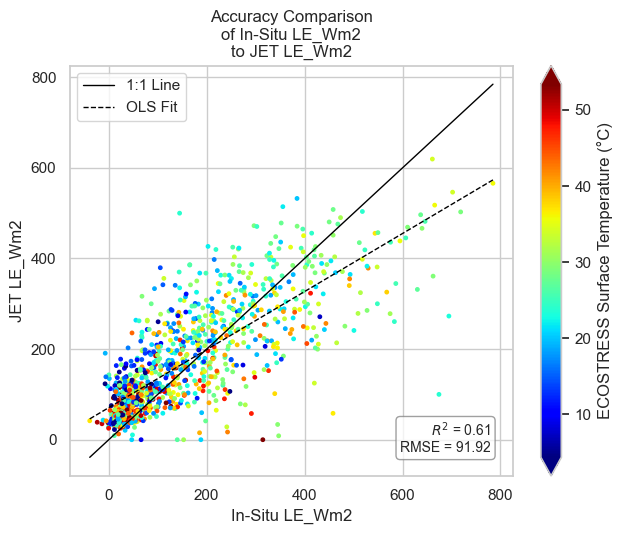

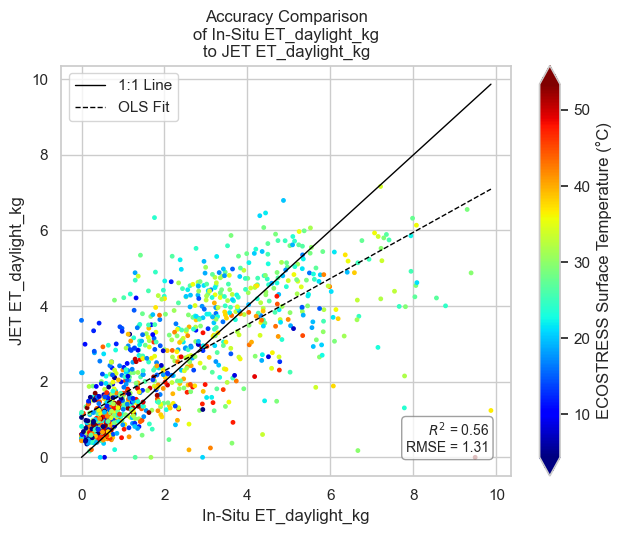

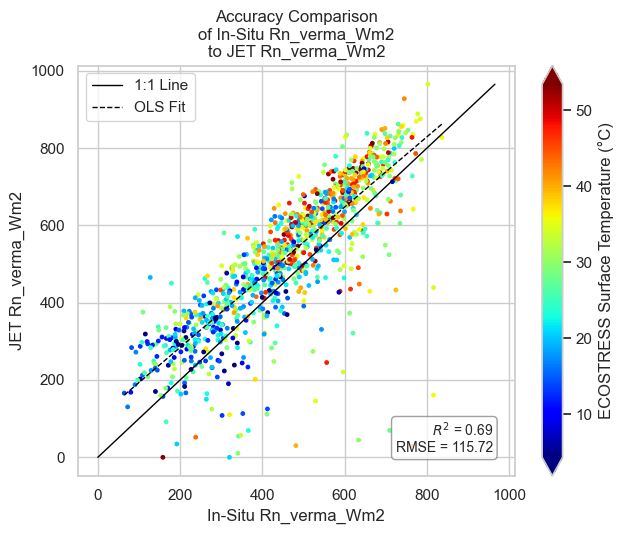

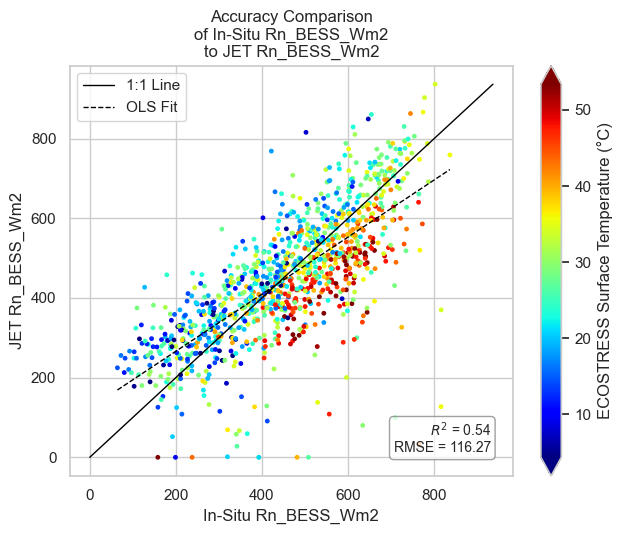

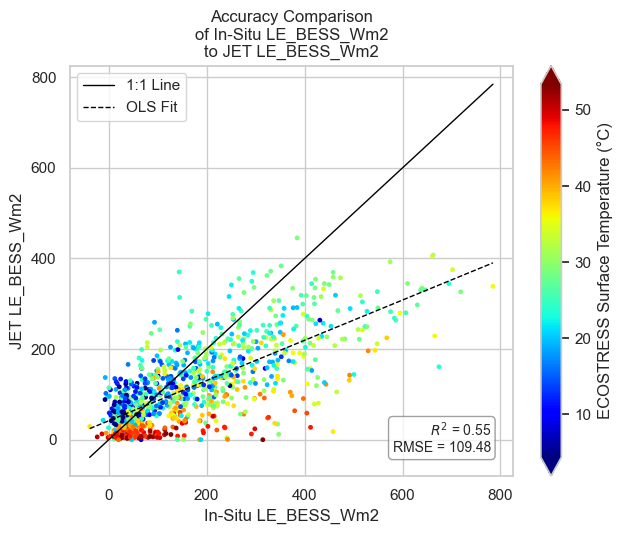

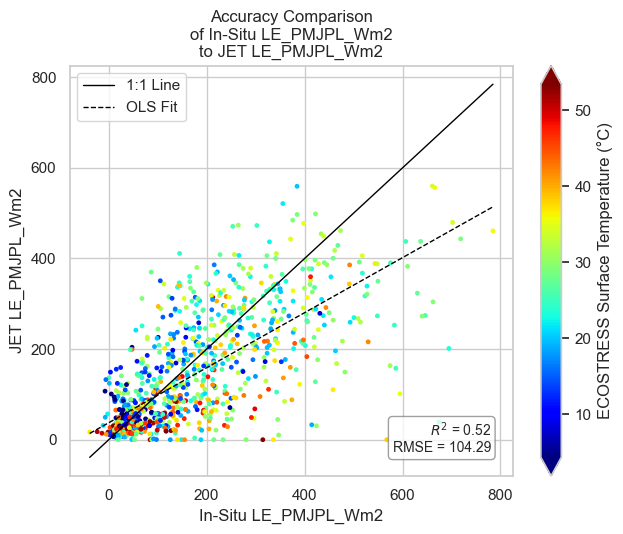

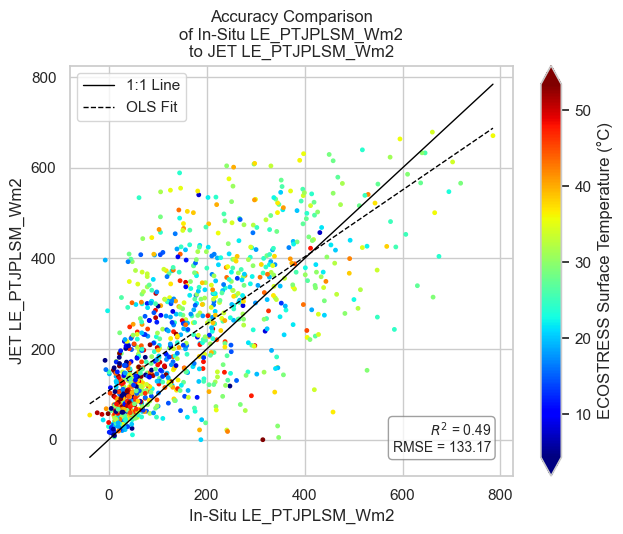

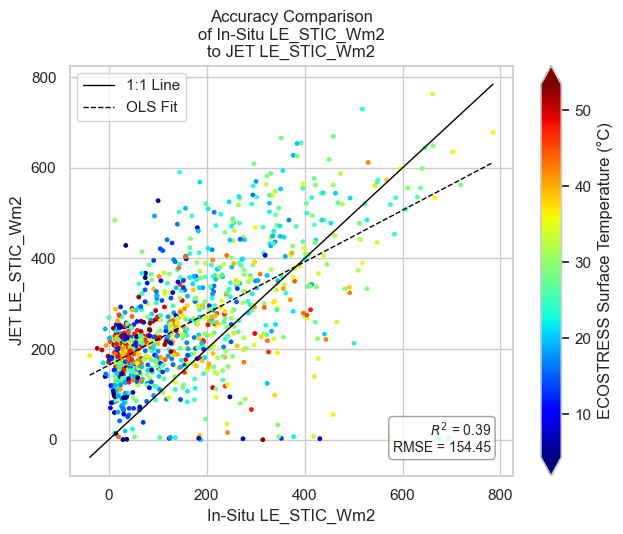

,SATM Slide Reference,Variable,N,R2,RMSE
0,Deck 1 Slides 4-5 (Ensemble LE),LE_Wm2,1063,0.6075,91.9180
1,Deck 1 Slide 4 (Ensemble Daily ET),ET_daylight_kg,1063,0.5569,1.3098
2,Deck 2 Slide 4 (Verma Rn),Rn_verma_Wm2,1059,0.6940,115.7151
3,Deck 2 Slide 4 (BESS-JPL Rn),Rn_BESS_Wm2,1063,0.5413,116.2662
4,Deck 1 Slide 8 / Deck 2 Slide 9 (BESS-JPL LE),LE_BESS_Wm2,1063,0.5465,109.4796
5,Deck 2 Slide 9 (PM-JPL LE),LE_PMJPL_Wm2,1059,0.5235,104.2911
6,Deck 2 Slide 9 (PT-JPL-SM LE),LE_PTJPLSM_Wm2,1059,0.4915,133.1736
7,Deck 1 Slide 9 / Deck 2 Slide 9 (STIC-JPL LE),LE_STIC_Wm2,1059,0.3904,154.4489


In [3]:
def generate_accuracy_plot(
    df: pd.DataFrame,
    x_variable: str,
    y_variable: str,
    output_variable: str,
    model_name: str = "JET",
    color_col: str = "ST_C",
    cbar_label: str = "ECOSTRESS Surface Temperature (°C)",
    save_plots: bool = SAVE_PLOTS,
):
    valid_data = df[[x_variable, y_variable, color_col]].dropna()
    vmin, vmax = np.percentile(valid_data[color_col], [2, 98])

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    sc = ax.scatter(
        x=valid_data[x_variable],
        y=valid_data[y_variable],
        c=valid_data[color_col],
        cmap="jet",
        s=6,
        vmin=vmin,
        vmax=vmax,
    )

    x_min, x_max = valid_data[x_variable].min(), valid_data[x_variable].max()
    y_min, y_max = valid_data[y_variable].min(), valid_data[y_variable].max()
    plot_min, plot_max = min(x_min, y_min), max(x_max, y_max)

    # 1:1 line
    ax.plot([plot_min, plot_max], [plot_min, plot_max], color="black", linestyle="-", linewidth=1, label="1:1 Line")

    # 1st-degree OLS regression line
    coefs = np.polyfit(valid_data[x_variable], valid_data[y_variable], 1)
    ols_x = np.array([x_min, x_max])
    ax.plot(ols_x, coefs[0] * ols_x + coefs[1], color="black", linestyle="--", linewidth=1, label="OLS Fit")

    # R^2 of linear fit and direct RMSE
    y_pred_ols = coefs[0] * valid_data[x_variable] + coefs[1]
    r2 = r2_score(valid_data[y_variable], y_pred_ols)
    rmse = np.sqrt(mean_squared_error(valid_data[x_variable], valid_data[y_variable]))

    ax.annotate(
        f"$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}",
        xy=(0.95, 0.05),
        xycoords="axes fraction",
        ha="right",
        va="bottom",
        fontsize=10,
        bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.75),
    )

    ax.grid(True, zorder=0)
    ax.set_xlabel(f"In-Situ {output_variable}")
    ax.set_ylabel(f"{model_name} {output_variable}")
    ax.set_title(f"Accuracy Comparison\nof In-Situ {output_variable}\nto {model_name} {output_variable}")
    plt.colorbar(sc, ax=ax, label=cbar_label, extend="both")
    ax.legend(loc="upper left")
    plt.tight_layout()

    if save_plots:
        fig.savefig(os.path.join(OUTPUT_DIR, f"Accuracy_{output_variable}.png"), dpi=200)
    plt.show()
    return {"Variable": output_variable, "N": len(valid_data), "R2": round(r2, 4), "RMSE": round(rmse, 4)}


satm_accuracy_targets = [
    ("insitu_LE_Wm2", "LE_Wm2", "Deck 1 Slides 4-5 (Ensemble LE)"),
    ("insitu_ET_daylight_kg", "ET_daylight_kg", "Deck 1 Slide 4 (Ensemble Daily ET)"),
    ("insitu_Rn_Wm2", "Rn_verma_Wm2", "Deck 2 Slide 4 (Verma Rn)"),
    ("insitu_Rn_Wm2", "Rn_BESS_Wm2", "Deck 2 Slide 4 (BESS-JPL Rn)"),
    ("insitu_LE_Wm2", "LE_BESS_Wm2", "Deck 1 Slide 8 / Deck 2 Slide 9 (BESS-JPL LE)"),
    ("insitu_LE_Wm2", "LE_PMJPL_Wm2", "Deck 2 Slide 9 (PM-JPL LE)"),
    ("insitu_LE_Wm2", "LE_PTJPLSM_Wm2", "Deck 2 Slide 9 (PT-JPL-SM LE)"),
    ("insitu_LE_Wm2", "LE_STIC_Wm2", "Deck 1 Slide 9 / Deck 2 Slide 9 (STIC-JPL LE)"),
]

accuracy_records = []
for x_col, y_col, slide_ref in satm_accuracy_targets:
    metrics = generate_accuracy_plot(processed_full, x_col, y_col, y_col)
    metrics["SATM Slide Reference"] = slide_ref
    accuracy_records.append(metrics)

accuracy_summary_df = pd.DataFrame(accuracy_records)[["SATM Slide Reference", "Variable", "N", "R2", "RMSE"]]
accuracy_summary_df

## 4. Monte Carlo One-at-a-Time Perturbation Sensitivity
Reproduces:
* **Deck 2 Slide 5:** Thermal sensitivity of `BESS-JPL` ($\approx 34.5\%$) vs. `Verma` ($\approx 17.7\%$) net radiation to `ST_C`, plus $\Delta ST_C$ vs. $\Delta R_n$ scatter plots.
* **Deck 2 Slides 10–11:** Sensitivity magnitude bar charts and $\Delta ST_C$ vs. $\Delta LE$ perturbation scatter plots for `PM-JPL` ($\approx 10\%$), `PT-JPL-SM` ($\approx 21\%$), `BESS-JPL` ($\approx 40\%$), and `STIC-JPL` ($\approx 138\%$).

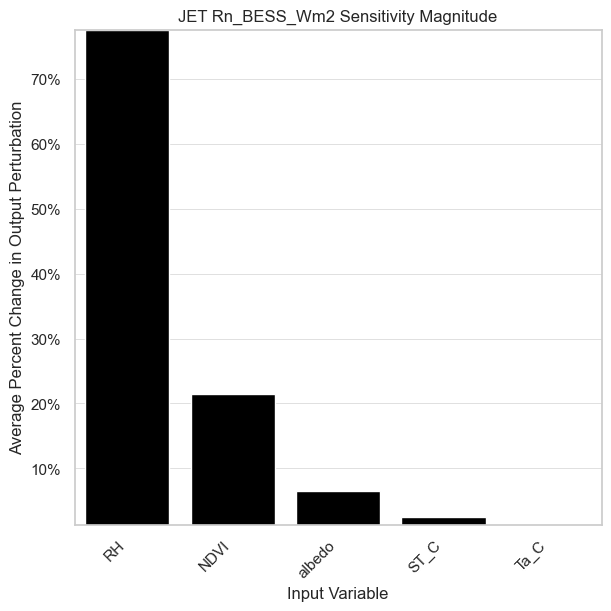

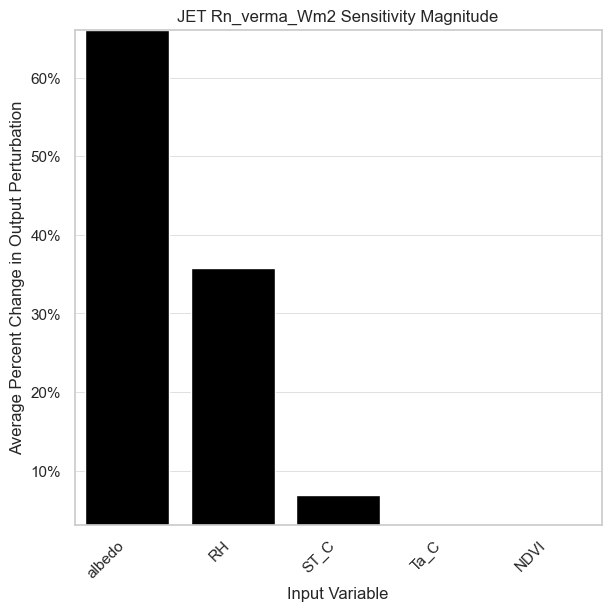

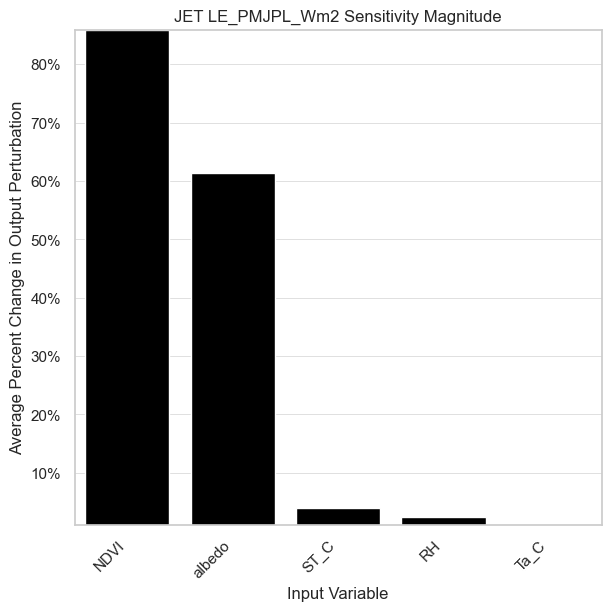

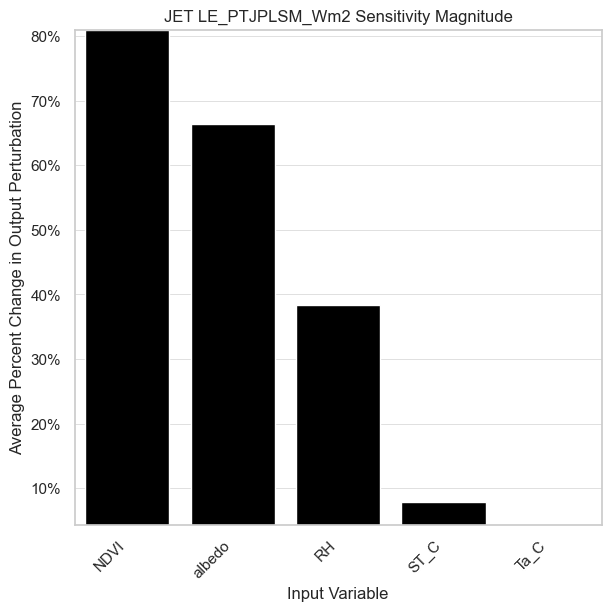

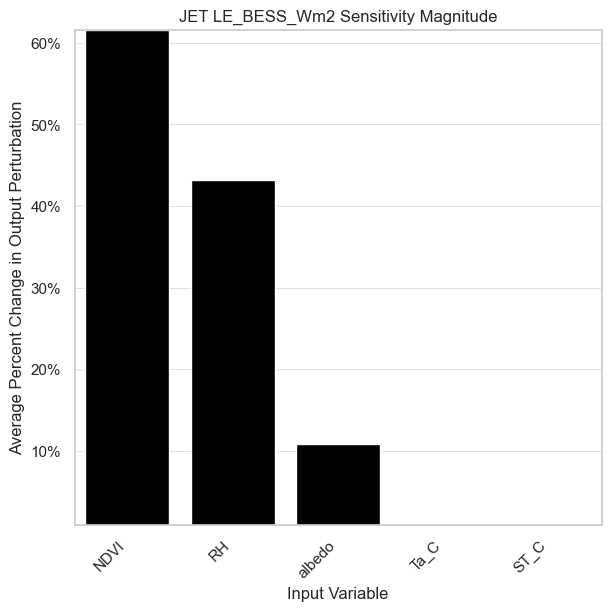

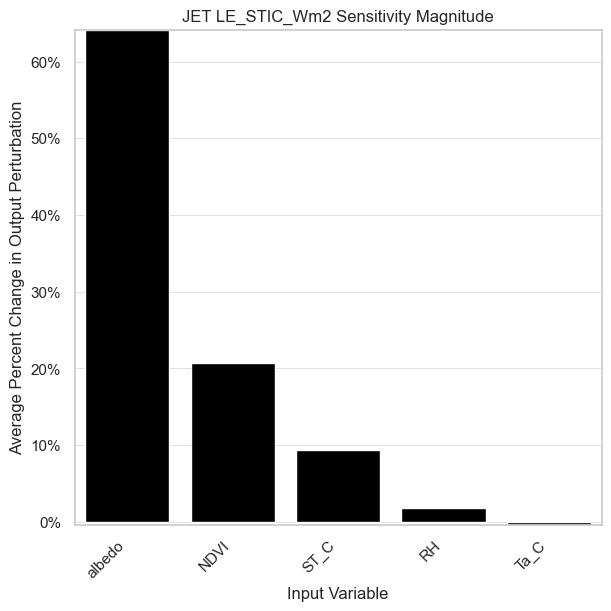

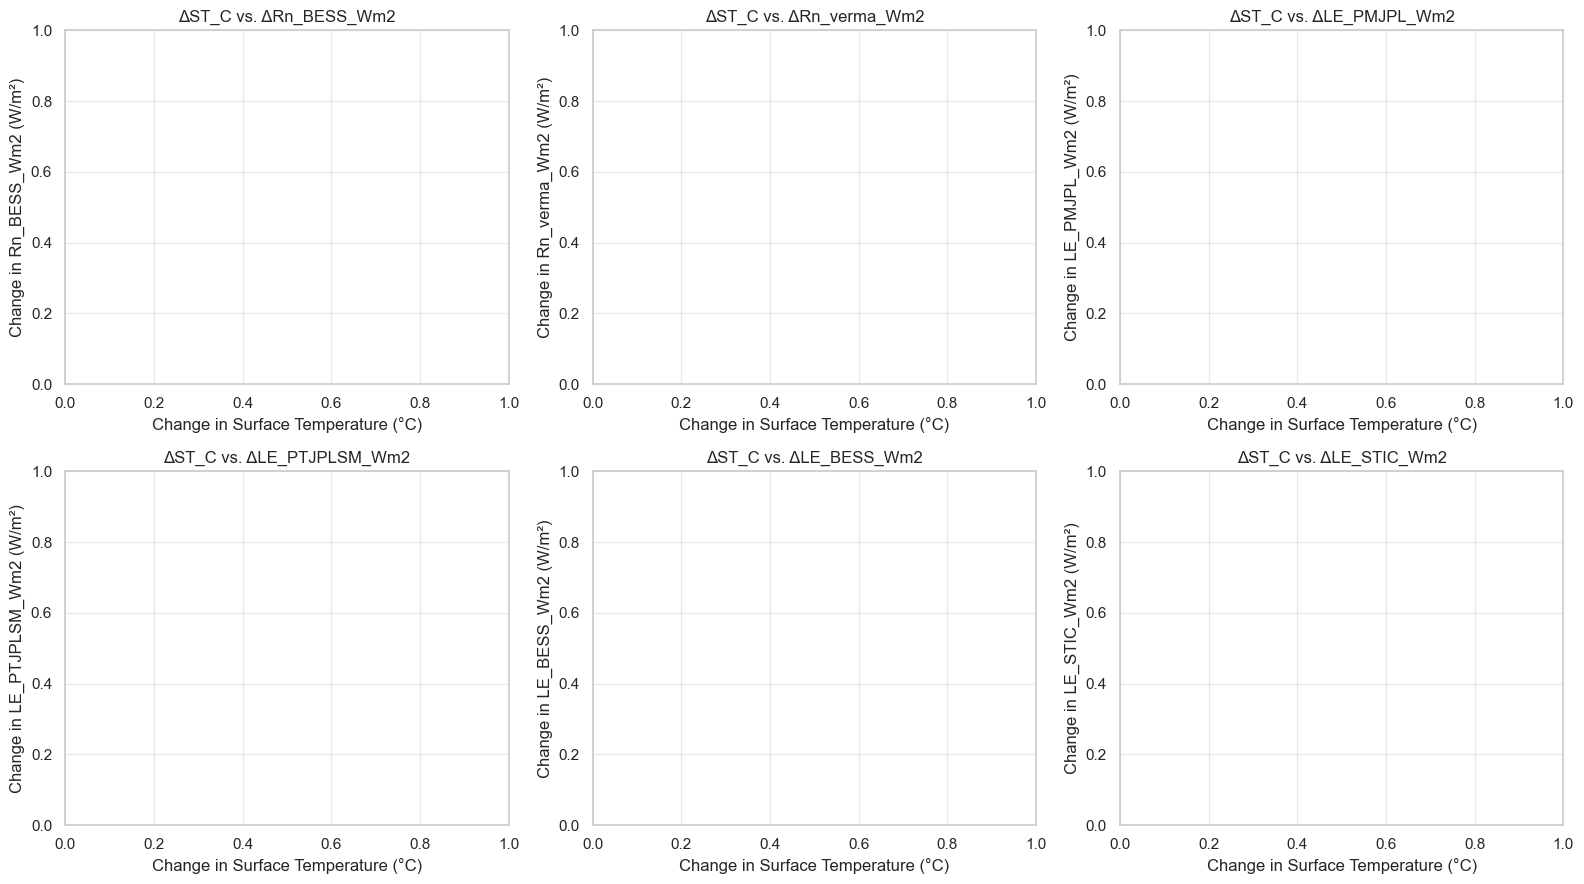

In [4]:
# Fixed Cell 4 — Monte Carlo One-at-a-Time Perturbation Sensitivity
mc_input_vars = ["ST_C", "NDVI", "albedo", "Ta_C", "RH"]
mc_output_vars = [
    "Rn_BESS_Wm2",
    "Rn_verma_Wm2",
    "LE_PMJPL_Wm2",
    "LE_PTJPLSM_Wm2",
    "LE_BESS_Wm2",
    "LE_STIC_Wm2",
]

mc_input_min = {"NDVI": 0.05, "albedo": 0.0, "RH": 0.0}
mc_input_max = {"NDVI": 1.0, "albedo": 1.0, "RH": 1.0}

with open(os.devnull, "w") as fnull, contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
    perturbed_df, sensitivity_metrics_df = sensitivity_analysis(
        input_df=input_df_full,
        forward_process=process_JET_table,
        input_variables=mc_input_vars,
        output_variables=mc_output_vars,
        input_min=mc_input_min,
        input_max=mc_input_max,
        normalization_function=divide_absolute_by_unperturbed,
    )

# 1. Magnitude Bar Charts (Deck 2 Slide 5 & Slide 10)
metric_name = sensitivity_metrics_df["metric"].iloc[0]
for out_var in mc_output_vars:
    sensitivity_magnitude_barchart(
        model_name="JET",
        output_variable=[out_var],
        df=sensitivity_metrics_df,
        metric=metric_name,
    )

# 2. Delta ST_C vs. Delta Output Scatter Plots (Deck 2 Slide 5 & Slide 11)
st_sub = perturbed_df[perturbed_df["input_variable"] == "ST_C"].copy() if "input_variable" in perturbed_df.columns else perturbed_df.copy()
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, out_var in zip(axes.flatten(), mc_output_vars):
    sub = st_sub[st_sub["output_variable"] == out_var] if "output_variable" in st_sub.columns else st_sub
    x_col = "input_change" if "input_change" in sub.columns else "ST_C_change"
    y_col = "output_change" if "output_change" in sub.columns else f"{out_var}_change"
    if x_col in sub.columns and y_col in sub.columns:
        valid = sub.dropna(subset=[x_col, y_col])
        c_vals = valid["ST_C"] if "ST_C" in valid.columns else valid[x_col]
        sc = ax.scatter(valid[x_col], valid[y_col], c=c_vals, cmap="jet", s=4, alpha=0.6)
        plt.colorbar(sc, ax=ax, label="ST_C (°C)")
    ax.set_title(f"ΔST_C vs. Δ{out_var}")
    ax.set_xlabel("Change in Surface Temperature (°C)")
    ax.set_ylabel(f"Change in {out_var} (W/m²)")
    ax.grid(True, alpha=0.4)
plt.tight_layout()
if SAVE_PLOTS:
    fig.savefig(os.path.join(OUTPUT_DIR, "MC_Delta_ST_C_MultiPanel.png"), dpi=200)
plt.show()

## 5. Sobol Global Sensitivity Indices ($S_1, S_T$) & LOWESS Main-Effect Curves
Reproduces:
* **Deck 2 Slides 6–8:** Sobol sensitivity bar charts and `Sampled ST_C` vs. `Absolute Rn` LOWESS curves for `Rn_BESS_Wm2` ($S_1 \approx 0.78, S_T \approx 0.85$) and `Rn_verma_Wm2` ($S_1 \approx 0.75, S_T \approx 0.75$).
* **Deck 2 Slides 12–13:** Sobol sensitivity bar charts for `LE_PTJPLSM_Wm2`, `LE_PMJPL_Wm2`, `LE_BESS_Wm2`, and `LE_STIC_Wm2`.
* **Deck 2 Slide 14:** `Sampled ST_C` vs. `Absolute LE` LOWESS main-effect curves across all four constituent `LE` models (Panels a, c, d on full $-13.19\text{–}86.11^\circ\text{C}$ bounds; Panel b on $[0, 50]^\circ\text{C}$ bounds).

=== Rn_BESS_Wm2 ===


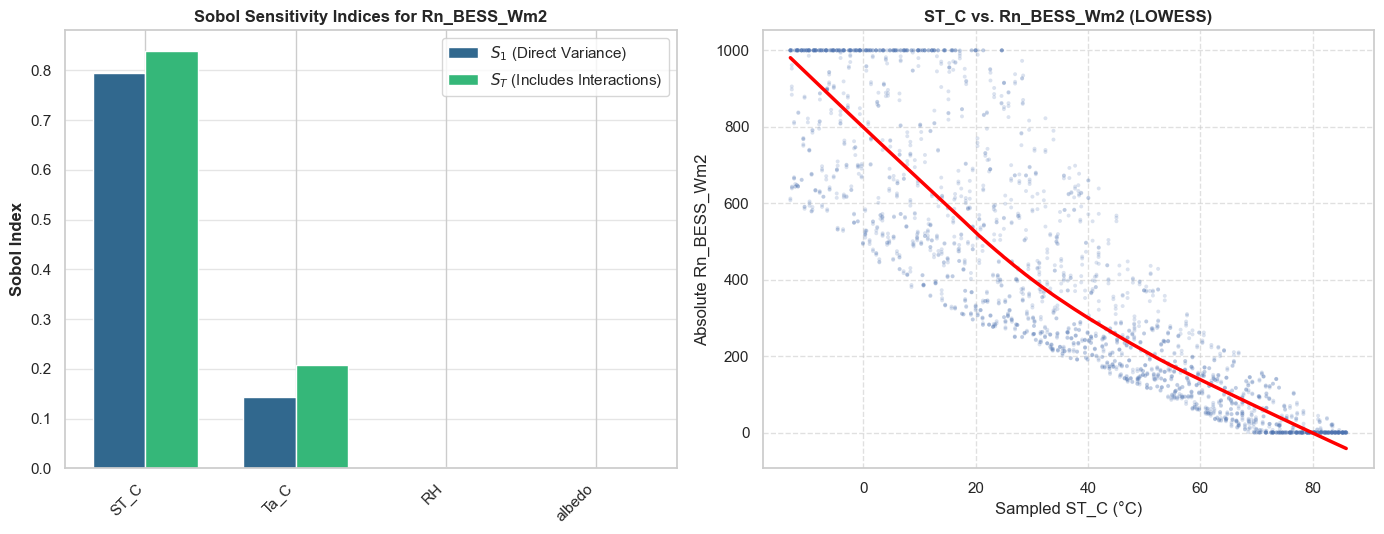

,Variable,S1,ST
0,ST_C,0.794,0.838
1,Ta_C,0.143,0.208
2,RH,0.002,0.001
3,albedo,0.000,0.000


=== Rn_verma_Wm2 ===


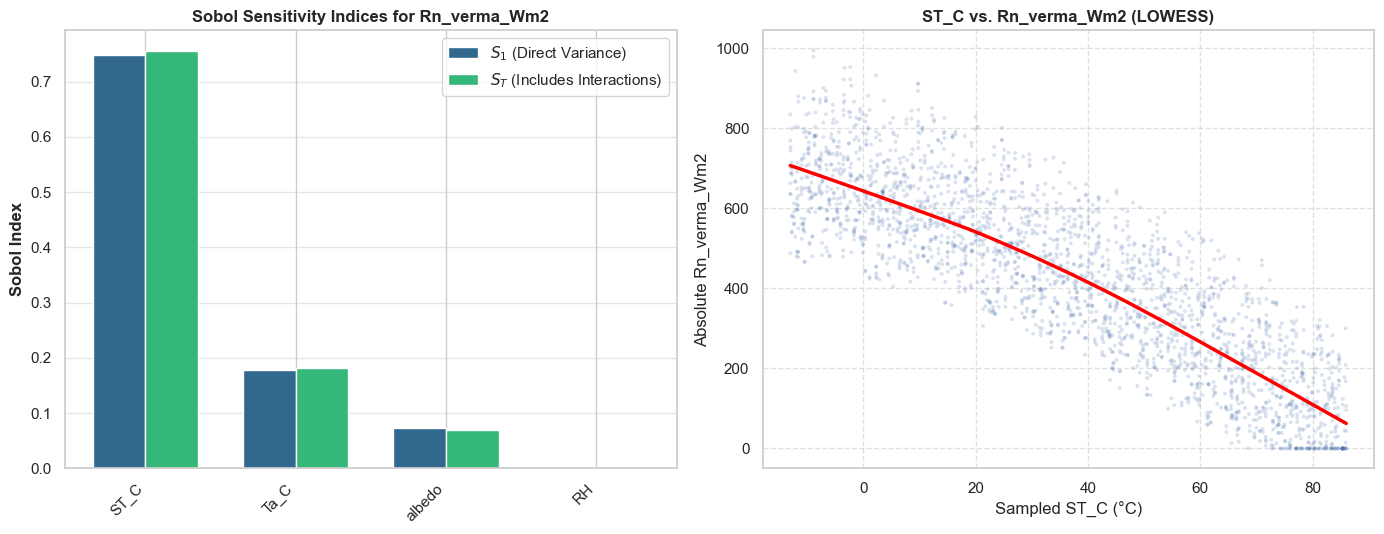

,Variable,S1,ST
0,ST_C,0.748,0.755
1,Ta_C,0.179,0.181
2,albedo,0.073,0.070
3,RH,0.002,0.003


=== LE_PTJPLSM_Wm2 (Full Bounds) ===


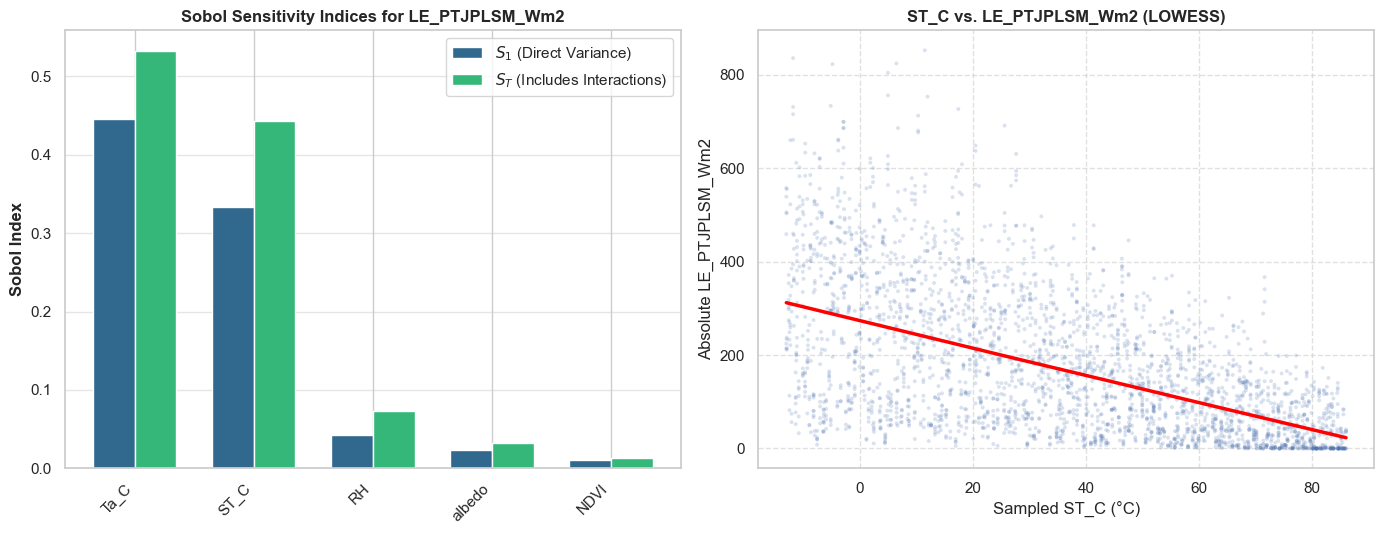

,Variable,S1,ST
0,Ta_C,0.445,0.532
1,ST_C,0.334,0.444
2,RH,0.043,0.073
3,albedo,0.023,0.032
4,NDVI,0.010,0.013


=== LE_PMJPL_Wm2 (Full Bounds) ===


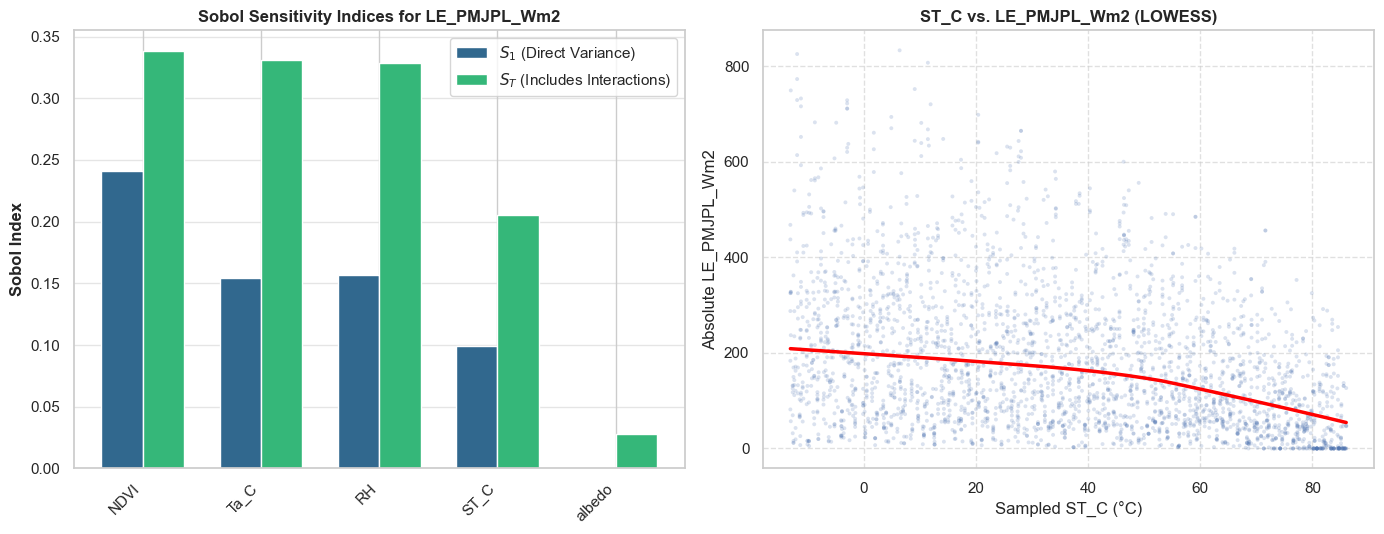

,Variable,S1,ST
0,NDVI,0.241,0.338
1,Ta_C,0.154,0.331
2,RH,0.157,0.328
3,ST_C,0.099,0.205
4,albedo,0.000,0.027


=== LE_BESS_Wm2 (Full Bounds) ===


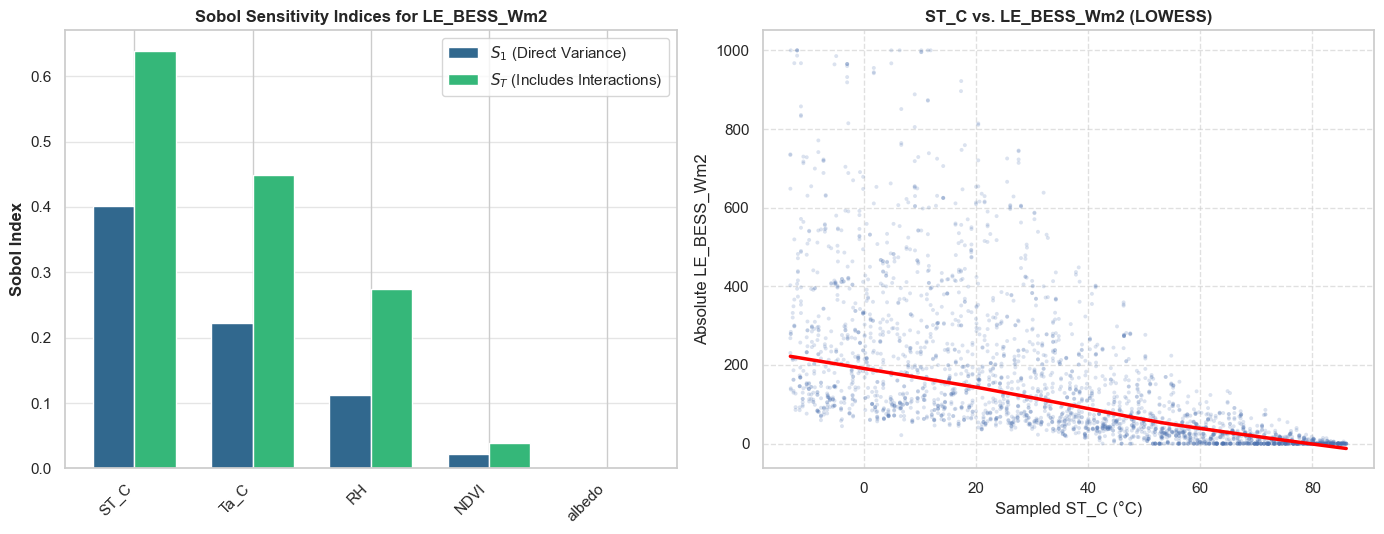

,Variable,S1,ST
0,ST_C,0.401,0.638
1,Ta_C,0.223,0.448
2,RH,0.112,0.275
3,NDVI,0.023,0.039
4,albedo,0.000,0.000


=== LE_STIC_Wm2 (Full Bounds) ===


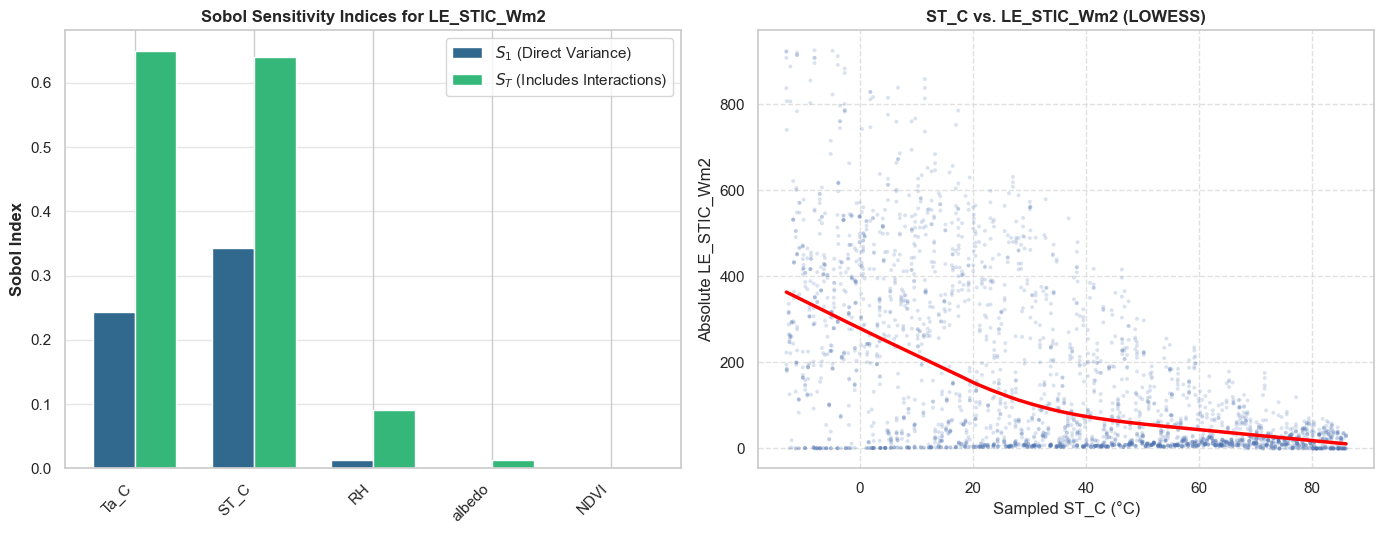

,Variable,S1,ST
0,Ta_C,0.244,0.649
1,ST_C,0.343,0.641
2,RH,0.013,0.091
3,albedo,0.002,0.014
4,NDVI,0.000,0.001


=== LE_BESS_Wm2 ([0, 50 C] Bounded Subset) ===


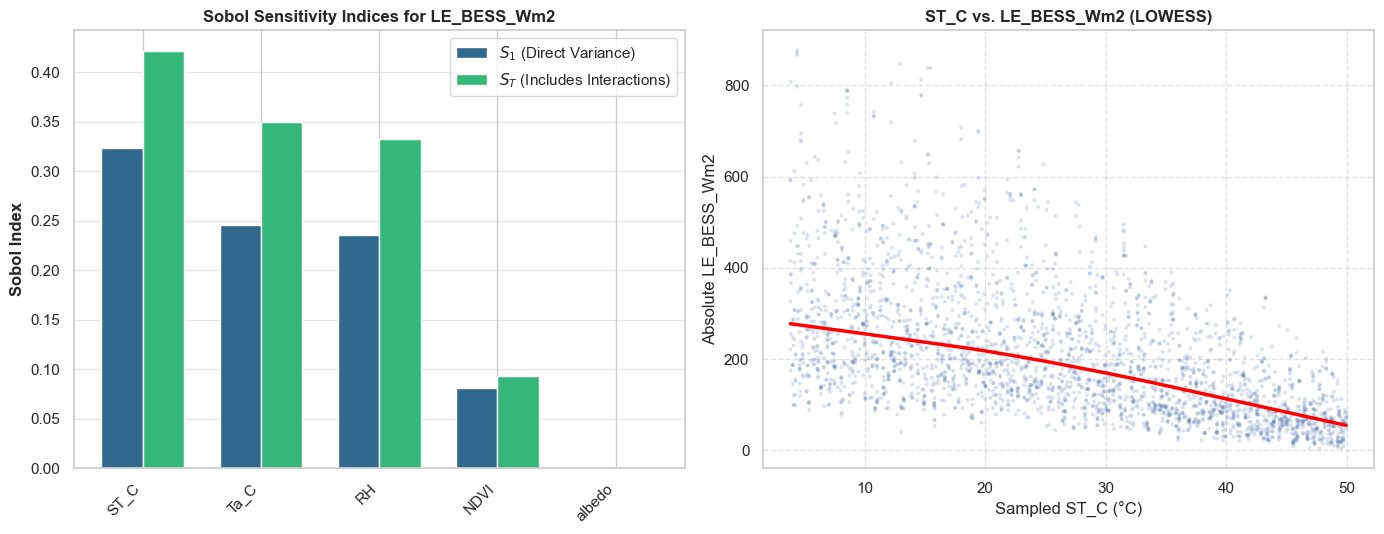

,Variable,S1,ST
0,ST_C,0.323,0.421
1,Ta_C,0.246,0.350
2,RH,0.236,0.332
3,NDVI,0.081,0.093
4,albedo,0.000,0.000


In [5]:
def sobol_sensitivity_and_lowess(
    df: pd.DataFrame,
    input_variables: list[str],
    target_output: str,
    N: int = 256,
    seed: int = 42,
    save_plots: bool = SAVE_PLOTS,
):
    df_clean = df.dropna(subset=[v for v in input_variables if v in df.columns])
    bounds = [[df_clean[v].min(), df_clean[v].max()] for v in input_variables]
    problem = {
        "num_vars": len(input_variables),
        "names": input_variables,
        "bounds": bounds,
    }

    param_values = sobol_sample.sample(problem, N, calc_second_order=True, seed=seed)

    # Broadcast median baseline row and inject Sobol samples
    base_row = df_clean.iloc[[0]].copy()
    for col, val in df_clean.select_dtypes(include=[np.number]).median().items():
        base_row[col] = val

    samples_df = pd.concat([base_row] * len(param_values), ignore_index=True)
    for i, var in enumerate(input_variables):
        samples_df[var] = param_values[:, i]

    with open(os.devnull, "w") as fnull, contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull):
        processed_samples = process_JET_table(samples_df)

    Y = processed_samples[target_output].values
    if np.isnan(Y).any():
        Y = np.nan_to_num(Y, nan=np.nanmean(Y))

    Si = sobol.analyze(problem, Y, calc_second_order=True)
    S1 = np.maximum(0, Si["S1"])
    ST = np.maximum(0, Si["ST"])

    order = np.argsort(ST)[::-1]
    sorted_vars = [input_variables[i] for i in order]
    sorted_S1 = S1[order]
    sorted_ST = ST[order]

    # Side-by-side figure: Sobol Bar Chart + ST_C LOWESS Main-Effect Scatter
    fig, (ax_bar, ax_lowess) = plt.subplots(1, 2, figsize=(14, 5.5))

    x = np.arange(len(sorted_vars))
    width = 0.35
    colors = sns.color_palette("viridis", n_colors=2)
    ax_bar.bar(x - width / 2, sorted_S1, width, label="$S_1$ (Direct Variance)", color=colors[0])
    ax_bar.bar(x + width / 2, sorted_ST, width, label="$S_T$ (Includes Interactions)", color=colors[1])
    ax_bar.set_ylabel("Sobol Index", fontweight="bold")
    ax_bar.set_title(f"Sobol Sensitivity Indices for {target_output}", fontweight="bold")
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(sorted_vars, rotation=45, ha="right")
    ax_bar.legend(frameon=True, facecolor="white")
    ax_bar.grid(axis="y", linestyle="-", alpha=0.5)

    plot_df = pd.DataFrame(param_values, columns=input_variables)
    plot_df[target_output] = Y
    sns.regplot(
        data=plot_df,
        x="ST_C",
        y=target_output,
        ax=ax_lowess,
        scatter_kws={"alpha": 0.2, "s": 8, "edgecolor": "none"},
        line_kws={"color": "red", "linewidth": 2.5},
        lowess=True,
    )
    ax_lowess.set_title(f"ST_C vs. {target_output} (LOWESS)", fontweight="bold")
    ax_lowess.set_xlabel("Sampled ST_C (°C)")
    ax_lowess.set_ylabel(f"Absolute {target_output}")
    ax_lowess.grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    if save_plots:
        fig.savefig(os.path.join(OUTPUT_DIR, f"Sobol_{target_output}.png"), dpi=200)
    plt.show()

    return pd.DataFrame({"Variable": sorted_vars, "S1": np.round(sorted_S1, 3), "ST": np.round(sorted_ST, 3)})


# 1. Net Radiation Sobol runs (Deck 2 Slides 6-8)
rn_vars = ["ST_C", "Ta_C", "RH", "albedo"]
for rn_target in ["Rn_BESS_Wm2", "Rn_verma_Wm2"]:
    print(f"=== {rn_target} ===")
    display(sobol_sensitivity_and_lowess(input_df_full, rn_vars, rn_target, N=256))

# 2. Constituent LE Sobol runs (Deck 2 Slides 12-14a, c, d)
le_vars = ["ST_C", "NDVI", "albedo", "Ta_C", "RH"]
for le_target in ["LE_PTJPLSM_Wm2", "LE_PMJPL_Wm2", "LE_BESS_Wm2", "LE_STIC_Wm2"]:
    print(f"=== {le_target} (Full Bounds) ===")
    display(sobol_sensitivity_and_lowess(input_df_full, le_vars, le_target, N=256))

# 3. Bounded [0, 50 C] BESS-JPL LOWESS curve (Deck 2 Slide 14b)
print("=== LE_BESS_Wm2 ([0, 50 C] Bounded Subset) ===")
display(sobol_sensitivity_and_lowess(input_df_270, le_vars, "LE_BESS_Wm2", N=256))

## 6. Diagnostic Addendum: Input Collinearity (VIF), Pairwise Interactions, & Meteorological Calibration
Reproduces the supporting diagnostics from the notebooks that explain the `PT-JPL-SM` Monte Carlo vs. Sobol discrepancy (Deck 2 Slide 15) and quantify the impact of `use_calibration=True`:
* **Pearson Correlation & VIF:** $r(\text{ST\_C}, \text{Ta\_C}) = 0.83$ and $r(\text{NDVI}, \text{RH}) = 0.73$.
* **Ensemble `ET_daylight_kg` & `LE_Wm2` Sobol + Pairwise Corner Grid:** Shows peak ET ($7\text{–}9\text{ kg}$) in the high-`Ta_C` ($>25^\circ\text{C}$), cool-`ST_C` ($<20^\circ\text{C}$), high-`RH` ($>0.7$) regime.
* **Calibration Comparison (`use_calibration=False` vs. `True` on $N = 270$):** Quantifies $R^2$ and RMSE improvements across `Ta_C`, `RH`, `Rn_Wm2`, `LE_Wm2`, and `ET_daylight_kg`.

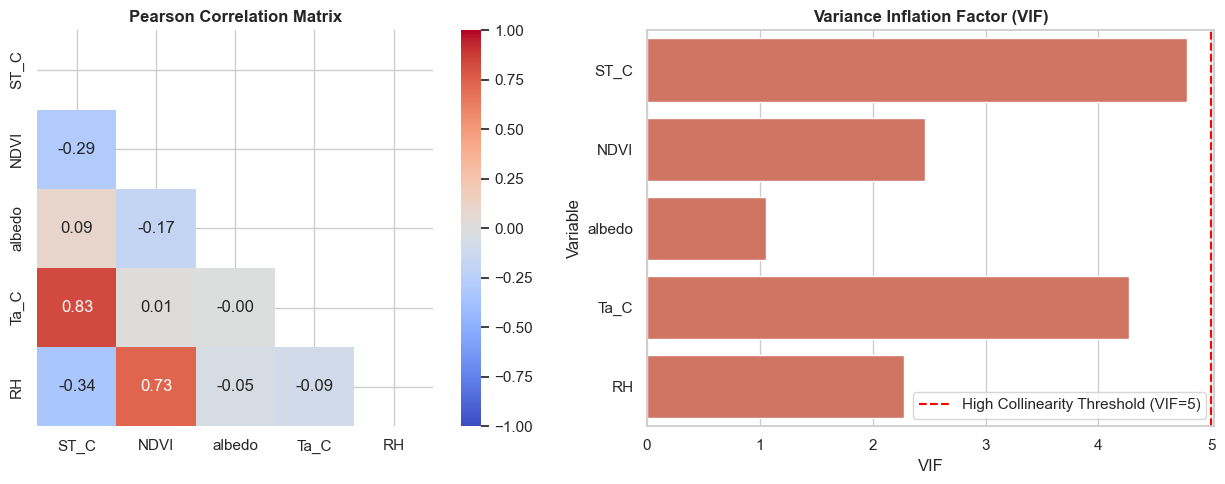

=== Ensemble ET_daylight_kg Sobol Sensitivity ===


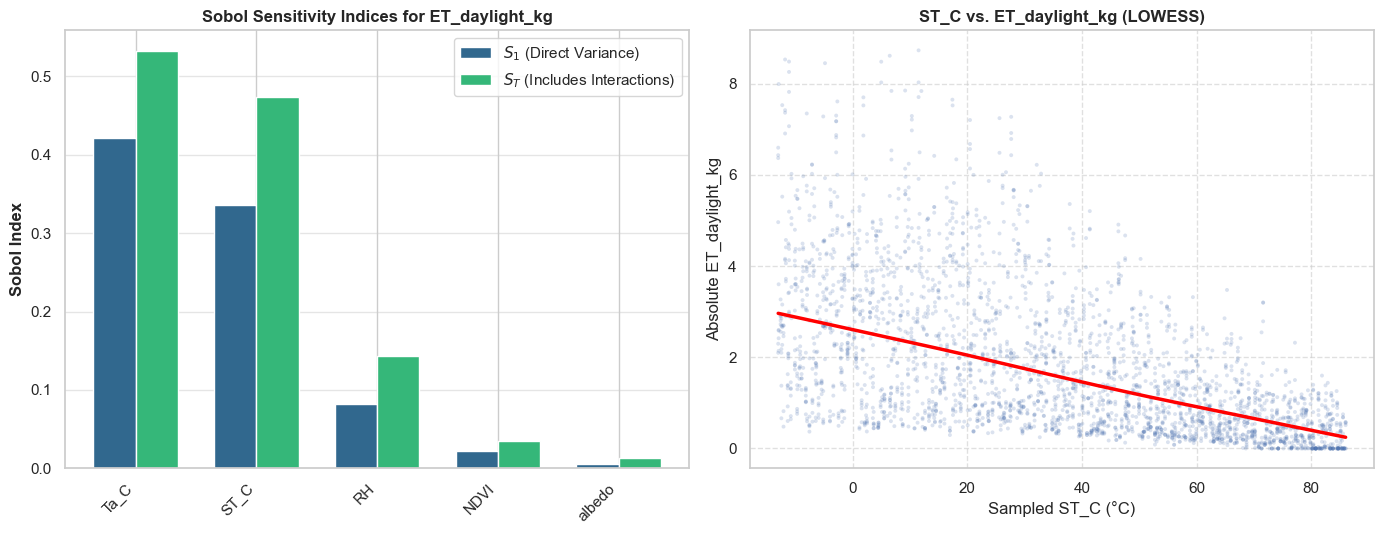

,Variable,S1,ST
0,Ta_C,0.422,0.532
1,ST_C,0.336,0.473
2,RH,0.082,0.143
3,NDVI,0.022,0.034
4,albedo,0.005,0.013


/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-

,Variable,R2 (Uncal),R2 (Cal),Delta R2,RMSE (Uncal),RMSE (Cal),RMSE % Improvement
0,ET_daylight_kg,0.537,0.562,+0.024,1.02,1.00,+2.6%
1,LE_Wm2,0.558,0.602,+0.044,68.86,65.33,+5.1%
2,Rn_Wm2,0.527,0.644,+0.117,108.59,94.18,+13.3%
3,G_Wm2,0.435,0.451,+0.016,46.43,45.76,+1.4%
4,H_Wm2,0.323,0.294,-0.029,102.90,105.11,-2.1%
5,Ta_C,0.813,0.914,+0.101,3.06,2.08,+32.1%
6,RH,0.033,0.701,+0.668,0.17,0.09,+44.4%
7,SWin_Wm2,0.812,0.812,+0.000,90.92,90.92,+0.0%


In [ ]:
# 1. Pearson Correlation Matrix & VIF (SOBOL Sensitivity 2 Cell 20)
col_vars = ["ST_C", "NDVI", "albedo", "Ta_C", "RH"]
X_col = input_df_270[col_vars].dropna()
corr_matrix = X_col.corr()

X_vif = X_col.copy()
X_vif["intercept"] = 1.0
vif_df = pd.DataFrame({
    "Variable": col_vars,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(len(col_vars))],
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap="coolwarm", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", square=True, ax=ax1)
ax1.set_title("Pearson Correlation Matrix", fontweight="bold")

sns.barplot(data=vif_df, x="VIF", y="Variable", color=sns.color_palette("coolwarm")[-1], ax=ax2)
ax2.axvline(x=5, color="red", linestyle="--", linewidth=1.5, label="High Collinearity Threshold (VIF=5)")
ax2.set_title("Variance Inflation Factor (VIF)", fontweight="bold")
ax2.legend()
plt.tight_layout()
plt.show()

# 2. Ensemble ET_daylight_kg Sobol Indices
print("=== Ensemble ET_daylight_kg Sobol Sensitivity ===")
display(sobol_sensitivity_and_lowess(input_df_full, col_vars, "ET_daylight_kg", N=256))

# 3. Calibration Impact Summary (Calibration Notebook Cell 15)
with open(os.devnull, "w") as fnull, contextlib.redirect_stdout(fnull), contextlib.redirect_stderr(fnull), warnings.catch_warnings():
    warnings.simplefilter("ignore")
    processed_270_cal = process_JET_table(input_df_270, use_calibration=True)

cal_summary = []
for var in ["ET_daylight_kg", "LE_Wm2", "Rn_Wm2", "G_Wm2", "H_Wm2", "Ta_C", "RH", "SWin_Wm2"]:
    insitu_col = f"insitu_{var}"
    if insitu_col in processed_270.columns and var in processed_270.columns:
        u_df = processed_270[[insitu_col, var]].dropna()
        c_df = processed_270_cal[[insitu_col, var]].dropna()
        r2_u = r2_score(u_df[insitu_col], u_df[var])
        rmse_u = np.sqrt(mean_squared_error(u_df[insitu_col], u_df[var]))
        r2_c = r2_score(c_df[insitu_col], c_df[var])
        rmse_c = np.sqrt(mean_squared_error(c_df[insitu_col], c_df[var]))
        cal_summary.append({
            "Variable": var,
            "R2 (Uncal)": round(r2_u, 3),
            "R2 (Cal)": round(r2_c, 3),
            "Delta R2": f"{r2_c - r2_u:+.3f}",
            "RMSE (Uncal)": round(rmse_u, 2),
            "RMSE (Cal)": round(rmse_c, 2),
            "RMSE % Improvement": f"{((rmse_u - rmse_c) / rmse_u) * 100:+.1f}%",
        })

pd.DataFrame(cal_summary)